# Single-Sérsic validation

A minimal BayMorph validation example for the fitting block.

This notebook generates a single-Sérsic mock galaxy with a known Gaussian PSF and known Gaussian noise, fits it with `DynestyFitter`, and compares the recovered parameters with the truth.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from baymorph.models import SersicModel
from baymorph.fitting import DynestyFitter
from baymorph.simulation.psf import GaussianPSF, convolve_with_psf
from baymorph.plotting import corner_plot, plot_fit_summary

In [2]:
shape = (101, 101)

truth = {
    "flux": 1.0e5,
    "re": 8.0,
    "n": 2.0,
    "q": 0.65,
    "theta": np.deg2rad(30.0),
    "x0": 50.0,
    "y0": 50.0,
}

psf = GaussianPSF(fwhm=3.0)
noise_sigma = 3.0
rng = np.random.default_rng(42)

clean_image = convolve_with_psf(
    SersicModel(**truth).render(shape),
    psf,
)

noise = np.full(shape, noise_sigma)
data = clean_image + rng.normal(0.0, noise_sigma, size=shape)

pd.DataFrame({
    "truth": {
        **truth,
        "theta": np.rad2deg(truth["theta"]),
        "theta_unit": "deg",
    }
})

,truth
flux,100000.0
re,8.0
n,2.0
q,0.65
theta,30.0
x0,50.0
y0,50.0
theta_unit,deg


In [3]:
prior_bounds = {
    "flux": (0.8e5, 1.2e5),
    "re": (4.0, 12.0),
    "n": (1.0, 4.0),
    "q": (0.4, 0.9),
    "theta": (-0.5 * np.pi, 0.5 * np.pi),
    "x0": (48.0, 52.0),
    "y0": (48.0, 52.0),
}

fitter = DynestyFitter(
    model_factory=SersicModel,
    data=data,
    noise=noise,
    parameter_names=list(truth),
    prior_bounds=prior_bounds,
    psf=psf,
    mask=None,
)

result = fitter.run(
    nlive=300,
    sample="rwalk",
    bound="multi",
    dlogz=0.01,
    seed=43,
    print_progress=True,
)

iter: 14463 | +300 | bound: 47 | nc: 1 | ncall: 372665 | eff(%):  3.965 | loglstar:   -inf < -25747.599 <    inf | logz: -25791.121 +/-  0.364 | dlogz:  0.000 >  0.010                               

In [4]:
best = result.best_parameters
median = result.median_parameters

summary = []
for name in result.parameter_names:
    true_value = truth[name]
    median_value = median[name]
    best_value = best[name]
    unit = ""

    if name == "theta":
        true_value = np.rad2deg(true_value)
        median_value = np.rad2deg(median_value)
        best_value = np.rad2deg(best_value)
        unit = "deg"

    summary.append({
        "parameter": name,
        "truth": true_value,
        "posterior_median": median_value,
        "maximum_likelihood": best_value,
        "ML_minus_truth": best_value - true_value,
        "unit": unit,
    })

pd.DataFrame(summary)

,parameter,truth,posterior_median,maximum_likelihood,ML_minus_truth,unit
0,flux,100000.00,100227.475876,100047.667478,47.667478,
1,re,8.00,8.019940,8.004754,0.004754,
2,n,2.00,2.024896,2.010250,0.010250,
3,q,0.65,0.649573,0.649452,-0.000548,
4,theta,30.00,30.023764,30.030434,0.030434,deg
5,x0,50.00,49.999827,50.000087,0.000087,
6,y0,50.00,50.000035,49.999739,-0.000261,


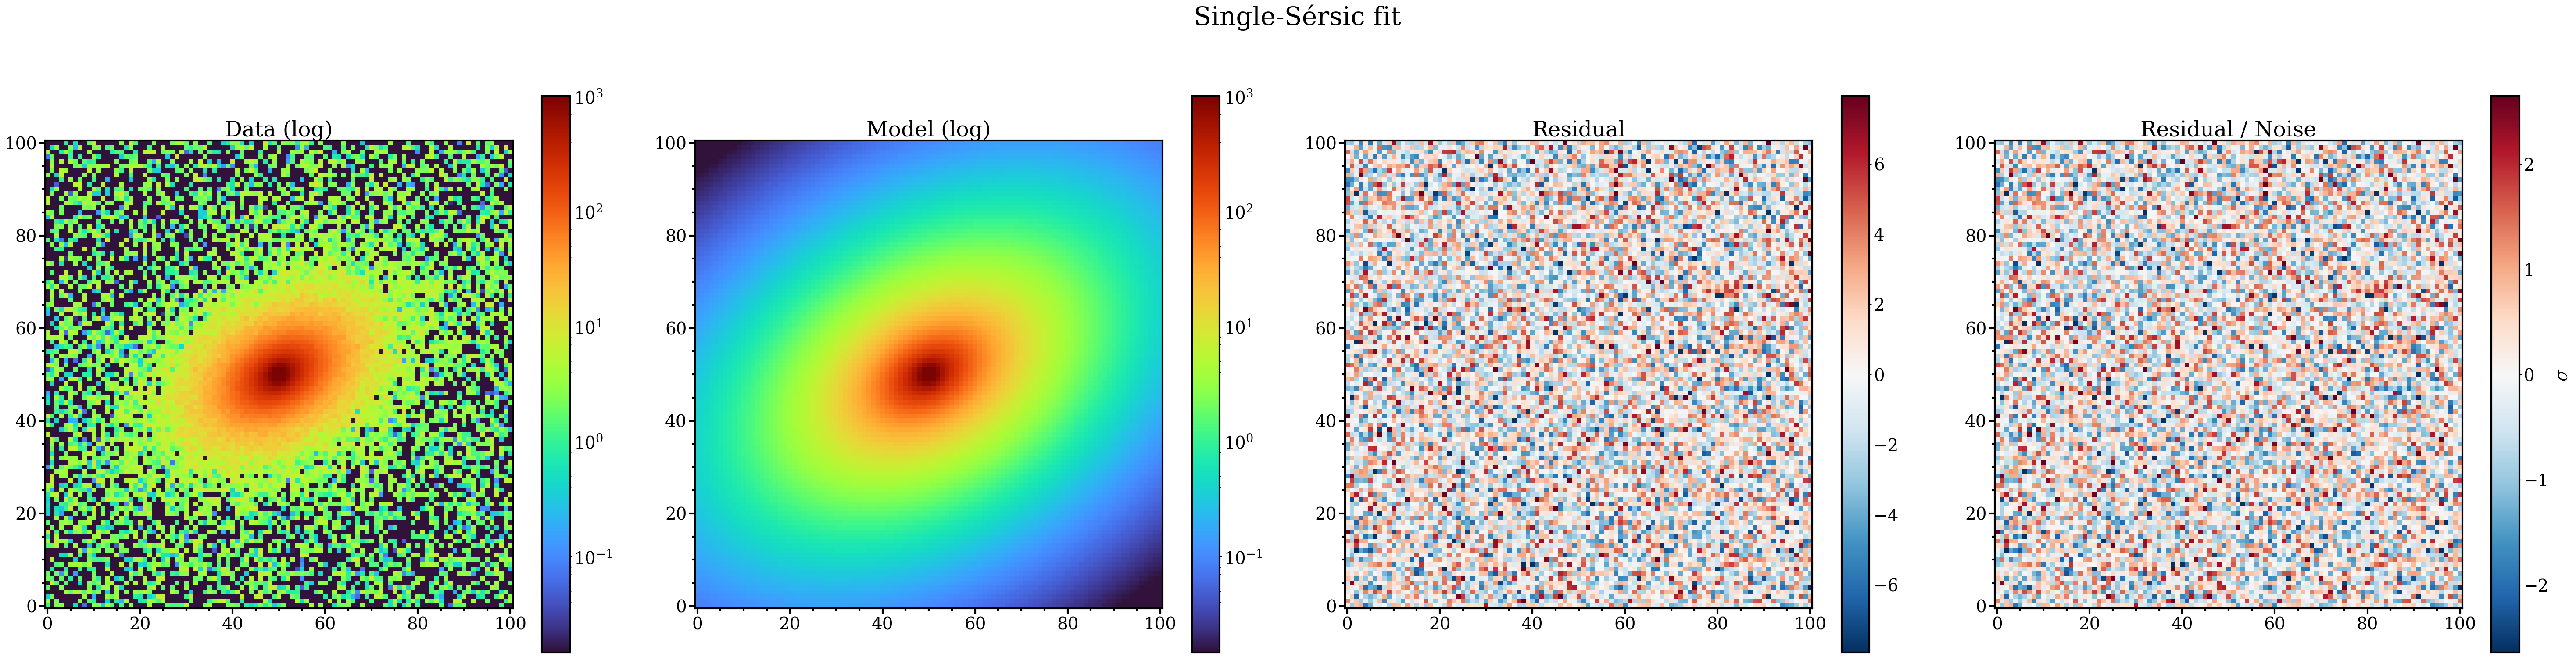

,value
chi2,10333.126238
reduced_chi2,1.013648
rms_residual,3.019366
max_abs_residual,13.190478


In [5]:
best_image = convolve_with_psf(
    SersicModel(**best).render(shape),
    psf,
)

plot_fit_summary(
    data=data,
    model=best_image,
    noise=noise,
    title="Single-Sérsic fit",
)
plt.show()

residual = data - best_image
dof = data.size - len(result.parameter_names)

pd.DataFrame.from_dict(
    {
        "chi2": np.sum((residual / noise) ** 2),
        "reduced_chi2": np.sum((residual / noise) ** 2) / dof,
        "rms_residual": np.sqrt(np.mean(residual**2)),
        "max_abs_residual": np.max(np.abs(residual)),
    },
    orient="index",
    columns=["value"],
)

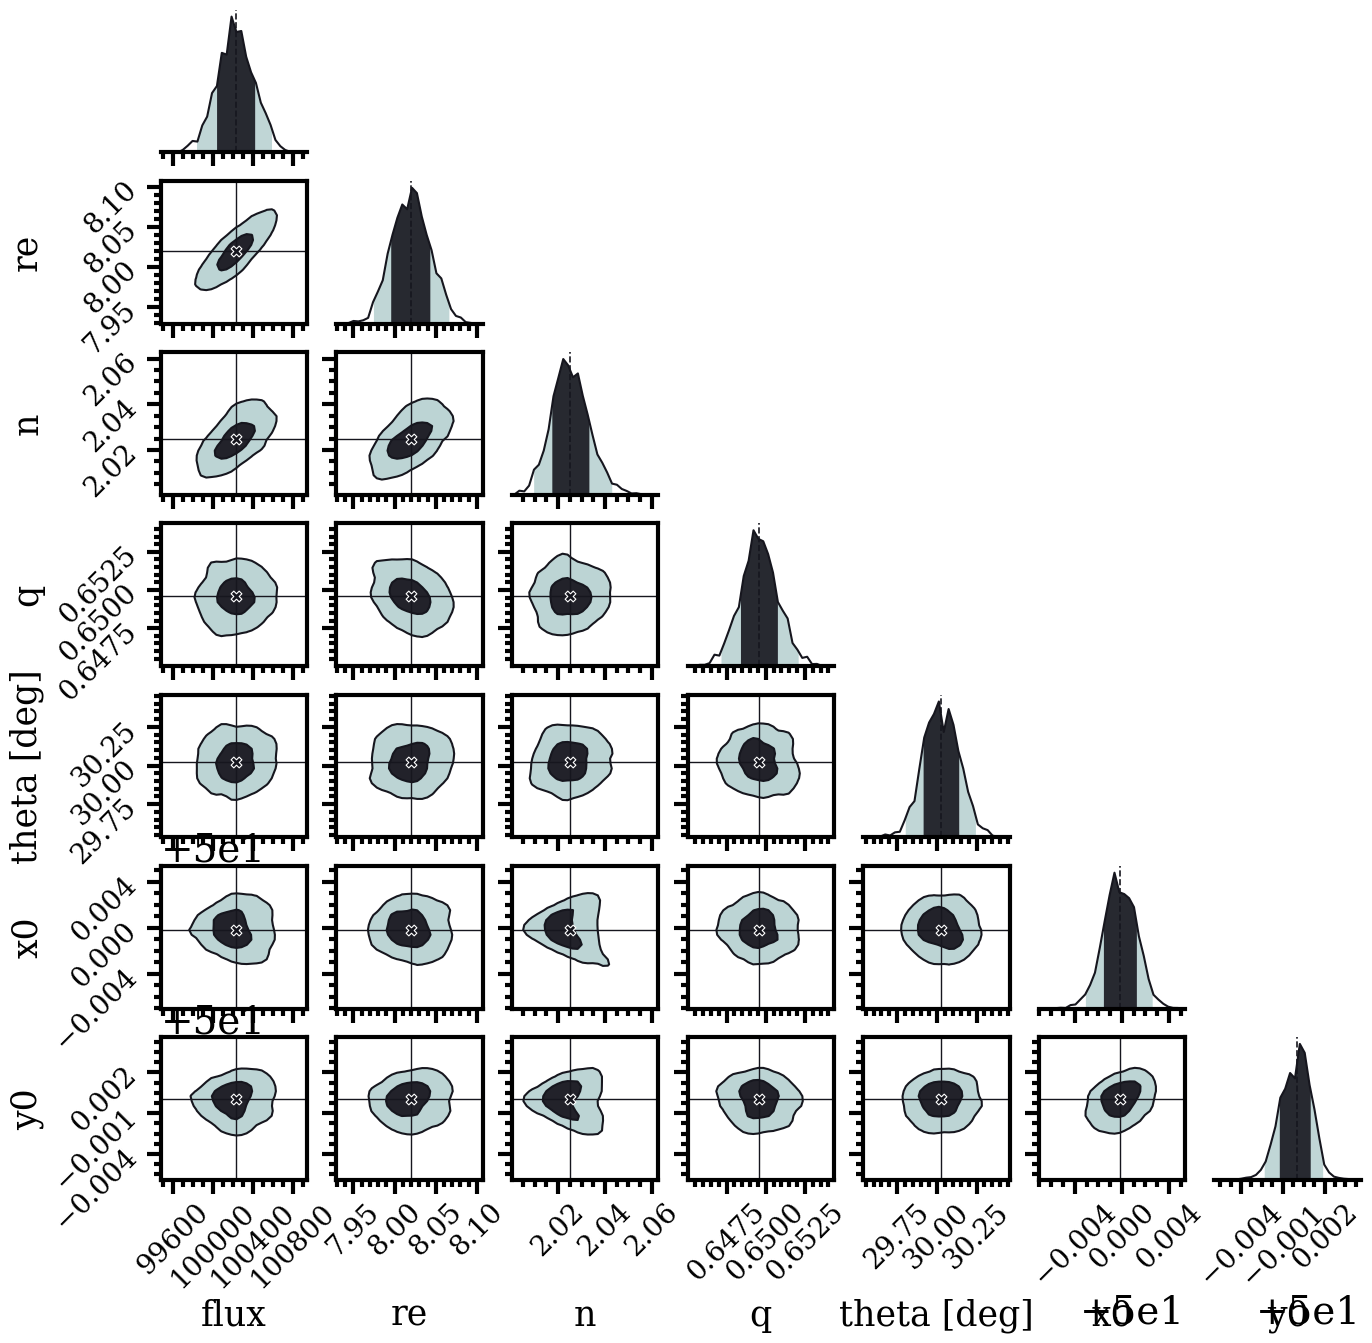

In [6]:
samples = result.posterior_samples.T.copy()
labels = result.parameter_names.copy()

theta_index = labels.index("theta")
samples[theta_index] = np.rad2deg(samples[theta_index])
labels[theta_index] = "theta [deg]"

corner_plot(
    samples,
    parameter_labels=labels,
    bins=30,
    show_medians=True,
)
plt.show()

A good validation run should recover the truth within the posterior uncertainty and give a reduced chi-square close to one, because the injected noise and the noise map are consistent.